# DFCI-Profile Glioma Cohort 2013–2018 (Touat et al., Nature 2020) — questions G1–G2

Source: Jacob's *CBIO thoughts* deck, slides 12–13. Data: `glioma_dfci_2020` from genie.cbioportal.org (REST download,
`data/genie_portal/download_log.csv`). 1,535 samples from 1,509 patients; OncoPanel v1–v3.

What this study has: per-patient OS from diagnosis, per-sample OS from sample collection (`SMP_OS_MOS`), per-sample flags for
**temozolomide / radiation / nitrosourea / bevacizumab given before the sample was collected**, sample type (primary vs recurrence),
IDH, MGMT, 1p/19q, and discrete CNA calls for ~500 genes. There is no regimen table.

**The bias at the centre of G1:** "TMZ before resection" marks samples resected *after* chemoradiation, i.e. mostly recurrence
resections. Those patients necessarily survived to a second surgery, so OS from diagnosis is inflated (immortal time). Three
corrections are shown: OS from sample collection, restriction to recurrence samples, and a Cox model left-truncated at sample collection.

Conventions as in `README.md`: `amp` = discrete CNA +2, `homdel` = −2; patients are compared for a gene only if their panel covers it.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "dfci_glioma"
F = []

P = cb.Portal("glioma_dfci_2020")
log = pd.read_csv(cb.DATA / "genie_portal" / "download_log.csv")
display(log[log.study_id == "glioma_dfci_2020"])
sm = P.samples_all
print(f"samples {len(sm)}, patients {sm.patient_id.nunique()}")
display(pd.crosstab(sm.CANCER_TYPE_DETAILED, sm.PRIOR_TREATMENT_TEMOZOLOMIDE, margins=True).sort_values("All", ascending=False).head(8))

,study_id,file,rows,md5
8,glioma_dfci_2020,clinical_attributes.tsv,21,38c2154f892603f2b7ee52c04c88f39a
9,glioma_dfci_2020,data_clinical_patient.tsv,1509,7636d8606e817e34b41e9bd5e1c4d97d
10,glioma_dfci_2020,data_clinical_sample.tsv,1535,e3f6afcfc19f3ac942f8164f23c71180
11,glioma_dfci_2020,data_timeline.tsv,0,68b329da9893e34099c7d8ad5cb9c940
12,glioma_dfci_2020,data_cna.tsv,761360,1d0f56f57d794423679e58d9ab7eb1ce
13,glioma_dfci_2020,data_mutations.tsv,13842,dc7ccac27265d0d47e1b28f1f01a4cd3
14,glioma_dfci_2020,gene_panel_per_sample.tsv,1535,7c525f20384fa47d35e1c7e4d6360f39


samples 1535, patients 1509


PRIOR_TREATMENT_TEMOZOLOMIDE,No,Yes,All
CANCER_TYPE_DETAILED,,,
All,1334,201,1535
Glioblastoma,791,135,926
Astrocytoma,97,5,102
Anaplastic astrocytoma,85,16,101
Oligodendroglioma,83,8,91
Pilocytic astrocytoma,67,2,69
Anaplastic oligodendroglioma,45,23,68
"Low-grade glioma, NOS",42,1,43


## Cohort: glioblastoma, one sample per patient
Patients with two samples (26 in the whole study) keep the TMZ-exposed sample if they have one, otherwise the first sample.

In [2]:
gbm = sm[sm.CANCER_TYPE_DETAILED == "Glioblastoma"].copy()
gbm["tmz"] = gbm.PRIOR_TREATMENT_TEMOZOLOMIDE.eq("Yes")
gbm = gbm.sort_values(["patient_id", "tmz"], ascending=[True, False]).drop_duplicates("patient_id").set_index("patient_id", drop=False)
S = P.survival().loc[P.survival().index.intersection(gbm.index)].copy()
S["tmz"] = np.where(gbm.tmz.reindex(S.index), "TMZ before resection", "no TMZ before resection")
S["sample_type"] = gbm.SAMPLE_TYPE.reindex(S.index).str.capitalize()
S["smp_time"] = pd.to_numeric(gbm.SMP_OS_MOS.reindex(S.index), errors="coerce")
S["entry"] = (S.time - S.smp_time).clip(lower=0)             # months from diagnosis to sample collection
S["idh"] = gbm.IDH1_IDH2_STATUS.reindex(S.index)
S["group"] = gbm.INTEGRATED_HISTOMOLECULAR_GROUP.reindex(S.index)
S["mgmt"] = gbm.MGMT_METHYLATION_STATUS.reindex(S.index)
S["rt"] = gbm.PRIOR_TREATMENT_RADIATION_THERAPY.reindex(S.index)
S["age"] = pd.to_numeric(S.AGE_AT_DIAGNOSIS, errors="coerce")
S["sex"] = S.SEX
display(cb.consort([("Samples in study", len(sm)), ("Glioblastoma samples", int((sm.CANCER_TYPE_DETAILED == "Glioblastoma").sum())),
                    ("Glioblastoma patients (one sample each)", len(gbm)), ("With OS from diagnosis", int(S.time.notna().sum()))]))
display(pd.crosstab([S.tmz], [S.sample_type], margins=True))
display(pd.crosstab(S.tmz, S.group, margins=True))
A = P.alterations(samples=gbm[["sample_id", "patient_id"]])
print(f"alteration matrix: {len(A.patients)} patients x {len(A.genes)} genes; samples with unknown panel: {A.n_unknown_panel}")

,step,n,dropped
0,Samples in study,1535,0
1,Glioblastoma samples,926,609
2,Glioblastoma patients (one sample each),913,13
3,With OS from diagnosis,913,0


sample_type,Primary,Recurrence,All
tmz,,,
TMZ before resection,0,135,135
no TMZ before resection,753,25,778
All,753,160,913


group,"Astrocytoma, IDH1/2-mutant","Glioblastoma, IDH1/2-wt",All
tmz,,,
TMZ before resection,33,102,135
no TMZ before resection,68,710,778
All,101,812,913


alteration matrix: 913 patients x 567 genes; samples with unknown panel: 0


## G1 (replicate) — Among glioblastoma, 135 patients who received temozolomide before resection had higher OS
Deck: log-rank p = 1.24e-8 (slides 12–13).

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_naive
0,no TMZ before resection,778,483,20.2,0.735,0.429,0.154,6.55e-10,0.492
1,TMZ before resection,135,92,45.1,0.962,0.742,0.375,6.55e-10,0.492


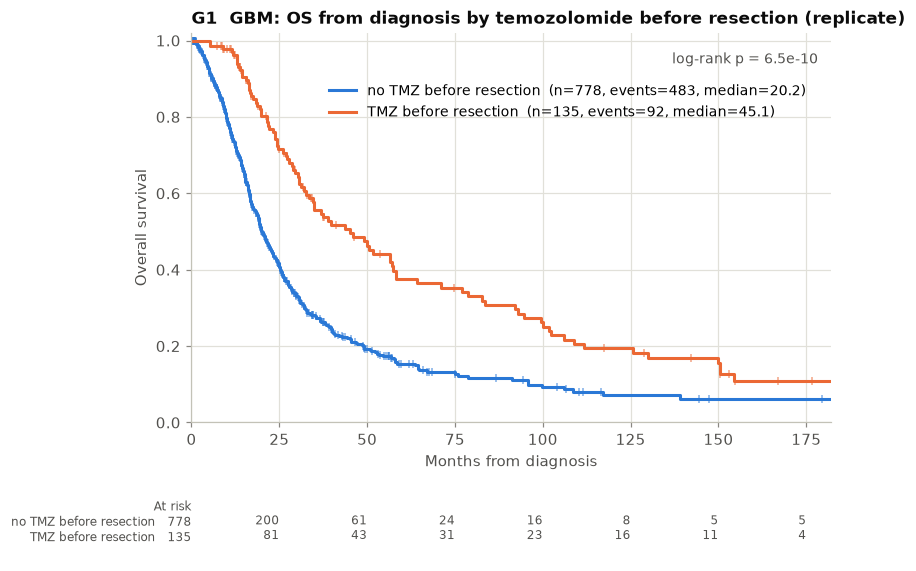

In [3]:
order = ["no TMZ before resection", "TMZ before resection"]
ax, tab1 = cb.km_plot(S, "tmz", order=order, title="G1  GBM: OS from diagnosis by temozolomide before resection (replicate)", xlabel="Months from diagnosis")
h1 = cb.hr(S.assign(feat=(S.tmz == order[1])), "feat")
tab1["HR_naive"] = h1["HR"]
cb.save(DS, "G1", table=tab1, fig=ax.figure, slug="os_from_dx_replicate")
display(tab1)

Corrections for immortal time: (a) OS measured from sample collection; (b) recurrence samples only; (c) Cox left-truncated at sample collection, adjusted for IDH status and age.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,no TMZ before resection,778,483,19.5,0.721,0.409,0.134,1.29e-13
1,TMZ before resection,135,92,11.5,0.467,0.118,0,1.29e-13


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,no TMZ before resection,25,11,139,1,0.875,0.657,0.0061
1,TMZ before resection,135,92,45.1,0.962,0.742,0.375,0.0061


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,no TMZ before resection,25,11,24.6,0.79,0.52,0.267,9.24e-05
1,TMZ before resection,135,92,11.5,0.467,0.118,0,9.24e-05


,model,HR,HR_lo,HR_hi,p_cox,n_cox
0,"naive, OS from dx",0.492,0.392,0.619,1.29e-09,913
1,left-truncated at sample collection,1.96,1.55,2.49,2.19e-08,911
2,left-truncated + IDH + age,1.98,1.57,2.51,1.31e-08,911
3,"recurrence only, OS from sample, + IDH + age",3.09,1.56,6.14,0.00128,160


[G1] replicated, but it is immortal-time bias: OS from dx: TMZ-before-resection n=135 median 45.1 vs 20.2 mo, log-rank p=6.5e-10 (deck 1.2e-8), naive HR 0.49. 135/135 TMZ-exposed samples are recurrences. OS from sample collection: median 11.5 vs 19.5 mo, p=1.3e-13; left-truncated HR 1.96, + IDH/age 1.98 (p=1.3e-08); recurrence-only from sample, adjusted: HR 3.09 (p=0.001).


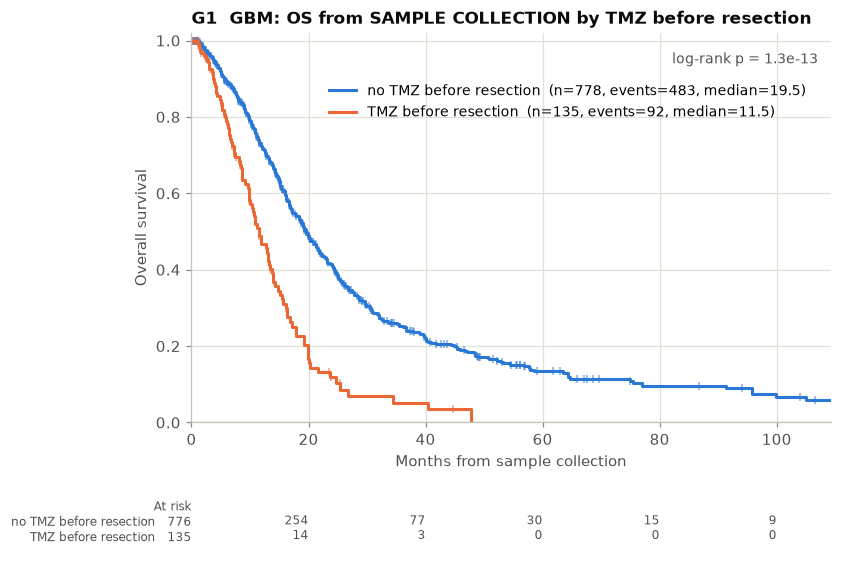

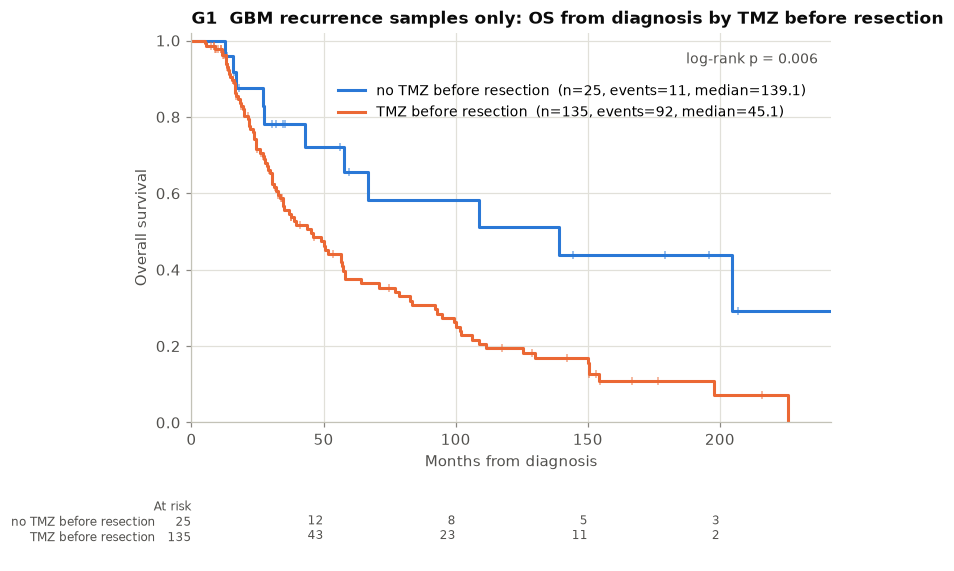

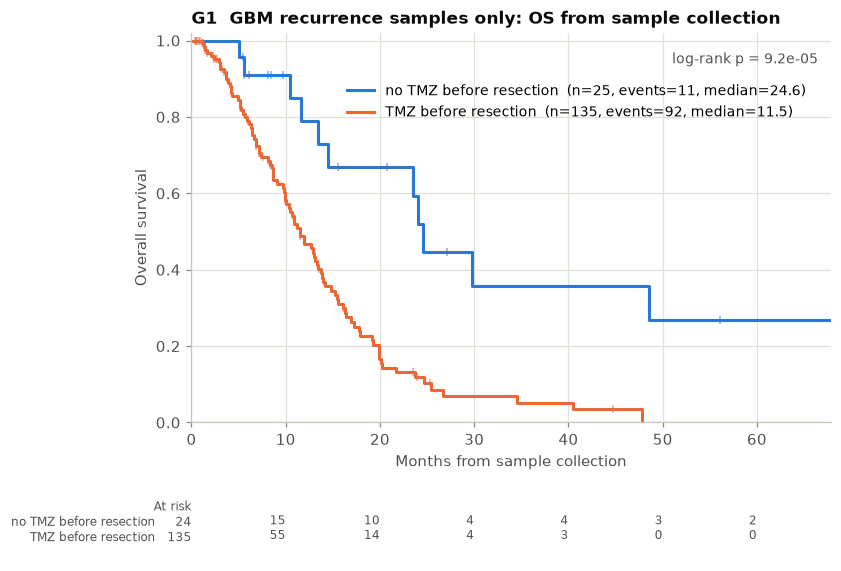

In [4]:
ax, tab1b = cb.km_plot(S, "tmz", time="smp_time", order=order, title="G1  GBM: OS from SAMPLE COLLECTION by TMZ before resection", xlabel="Months from sample collection")
cb.save(DS, "G1", table=tab1b, fig=ax.figure, slug="os_from_sample")
display(tab1b)
rec = S[S.sample_type == "Recurrence"]
ax, tab1c = cb.km_plot(rec, "tmz", order=order, title="G1  GBM recurrence samples only: OS from diagnosis by TMZ before resection", xlabel="Months from diagnosis")
cb.save(DS, "G1", table=tab1c, fig=ax.figure, slug="recurrence_only_from_dx")
display(tab1c)
ax, tab1d = cb.km_plot(rec, "tmz", time="smp_time", order=order, title="G1  GBM recurrence samples only: OS from sample collection", xlabel="Months from sample collection")
cb.save(DS, "G1", table=tab1d, fig=ax.figure, slug="recurrence_only_from_sample")
display(tab1d)
h_lt = cb.hr(S.assign(feat=(S.tmz == order[1])), "feat", entry="entry")
h_lta = cb.hr(S.assign(feat=(S.tmz == order[1])), "feat", entry="entry", adjust=["idh", "age"])
h_rec = cb.hr(rec.assign(feat=(rec.tmz == order[1])), "feat", time="smp_time", adjust=["idh", "age"])
cox = pd.DataFrame([dict(model="naive, OS from dx", **h1), dict(model="left-truncated at sample collection", **h_lt),
                    dict(model="left-truncated + IDH + age", **h_lta), dict(model="recurrence only, OS from sample, + IDH + age", **h_rec)])
cb.save(DS, "G1", table=cox, slug="cox_models")
display(cox)
cb.finding("G1", "replicated, but it is immortal-time bias",
           f"OS from dx: TMZ-before-resection n={tab1.n[1]} median {tab1.median_months[1]} vs {tab1.median_months[0]} mo, log-rank p={cb.fmt_p(tab1.p_logrank[0])} (deck 1.2e-8), naive HR {h1['HR']:.2f}. "
           f"{int((rec.tmz == order[1]).sum())}/{int((S.tmz == order[1]).sum())} TMZ-exposed samples are recurrences. OS from sample collection: median {tab1b.median_months[1]} vs {tab1b.median_months[0]} mo, p={cb.fmt_p(tab1b.p_logrank[0])}; "
           f"left-truncated HR {h_lt['HR']:.2f}, + IDH/age {h_lta['HR']:.2f} (p={cb.fmt_p(h_lta['p_cox'])}); recurrence-only from sample, adjusted: HR {h_rec['HR']:.2f} (p={cb.fmt_p(h_rec['p_cox'])}).", F)

## G2 — How does each CNA affect OS within each TMZ group? Do patients with CDKN2A/CDKN2B and MTAP deletions do worse?
Deck gene list (slide 13): CDKN2A, CDKN2B, MTAP, PTEN deep deletions; EGFR, CDK4, PDGFRA, MDM2, MDM4, PIK3C2B, GLI1 amplifications.
Within each TMZ group: OS from diagnosis (as in the deck) and OS from sample collection; HR adjusted for IDH status and age (left-truncated at sample collection); BH FDR within each stratum; features with fewer than 10 carriers or non-carriers in a stratum are skipped.

In [5]:
CNA_GENES = {"CDKN2A": "homdel", "CDKN2B": "homdel", "MTAP": "homdel", "PTEN": "homdel", "EGFR": "amp", "CDK4": "amp",
             "PDGFRA": "amp", "MDM2": "amp", "MDM4": "amp", "PIK3C2B": "amp", "GLI1": "amp"}
rows = []
for stratum in order + ["all GBM"]:
    Ss = S if stratum == "all GBM" else S[S.tmz == stratum]
    for g, k in CNA_GENES.items():
        st = A.status(g, k)
        d, t = cb.compare(Ss, st, labels=("no", "yes"), entry="entry", adjust=["idh", "age"])
        if t.n.min() < 10:
            continue
        d2, t2 = cb.compare(Ss, st, labels=("no", "yes"), time="smp_time", adjust=["idh", "age"])
        rows.append(dict(stratum=stratum, feature=f"{g} {k}", gene=g, kind=k, n_alt=t.n[1], n_wt=t.n[0], pct=round(100 * t.n[1] / t.n.sum(), 1),
                         median_alt=t.median_months[1], median_wt=t.median_months[0], p_logrank=t.p_logrank[0],
                         HR=t.attrs["HR"], HR_lo=t.attrs["HR_lo"], HR_hi=t.attrs["HR_hi"], p_cox=t.attrs["p_cox"],
                         median_alt_from_sample=t2.median_months[1], median_wt_from_sample=t2.median_months[0], p_logrank_from_sample=t2.p_logrank[0],
                         HR_from_sample=t2.attrs["HR"]))
g2 = pd.DataFrame(rows)
g2["q_bh"] = np.nan
for s_, idx in g2.groupby("stratum").groups.items():
    g2.loc[idx, "q_bh"] = cb.multipletests(g2.loc[idx, "p_logrank"], method="fdr_bh")[1]
g2 = g2.sort_values(["stratum", "p_logrank"]).reset_index(drop=True)
cb.save(DS, "G2", table=g2, slug="cna_by_tmz_group")
display(g2[["stratum", "feature", "n_alt", "pct", "median_alt", "median_wt", "p_logrank", "q_bh", "HR", "HR_lo", "HR_hi", "median_alt_from_sample", "median_wt_from_sample", "p_logrank_from_sample", "HR_from_sample"]])

,stratum,feature,n_alt,pct,median_alt,median_wt,p_logrank,q_bh,HR,HR_lo,HR_hi,median_alt_from_sample,median_wt_from_sample,p_logrank_from_sample,HR_from_sample
0,TMZ before resection,EGFR amp,24,17.8,26,51.7,0.00107,0.0064,1.3,0.698,2.41,9.9,12.9,0.0367,1.78
1,TMZ before resection,MTAP homdel,22,16.3,102,43.6,0.186,0.454,0.743,0.334,1.65,9.9,11.5,0.812,1.05
2,TMZ before resection,CDK4 amp,13,9.6,31.2,46,0.227,0.454,0.729,0.355,1.5,11.5,11.5,0.455,0.685
3,TMZ before resection,PDGFRA amp,10,7.4,34.8,46,0.659,0.979,1,0.416,2.4,11.5,11.5,0.594,0.86
4,TMZ before resection,CDKN2A homdel,49,36.3,45.1,43.6,0.939,0.979,1.52,0.958,2.4,8.7,13.3,0.000736,2.22
5,TMZ before resection,CDKN2B homdel,48,35.6,56.6,38.8,0.979,0.979,1.41,0.879,2.25,9.8,13.1,0.00435,1.96
6,all GBM,CDKN2A homdel,369,40.4,21.3,24.6,0.00549,0.0307,1.22,1.03,1.44,16.9,19.2,0.00262,1.16
7,all GBM,EGFR amp,252,27.6,21.6,23.2,0.00557,0.0307,0.863,0.713,1.05,19.4,17.2,0.983,0.831
8,all GBM,MDM2 amp,58,6.4,19.5,23.5,0.0176,0.0382,1.05,0.751,1.48,19.1,17.9,0.316,1.03
9,all GBM,MDM4 amp,47,5.1,16.7,23.2,0.0201,0.0382,1.49,1.04,2.13,14.6,18.7,0.00628,1.46


PosixPath('/Users/daniel/Code/explore-genie/results/dfci_glioma/G2_forest_by_tmz_group')

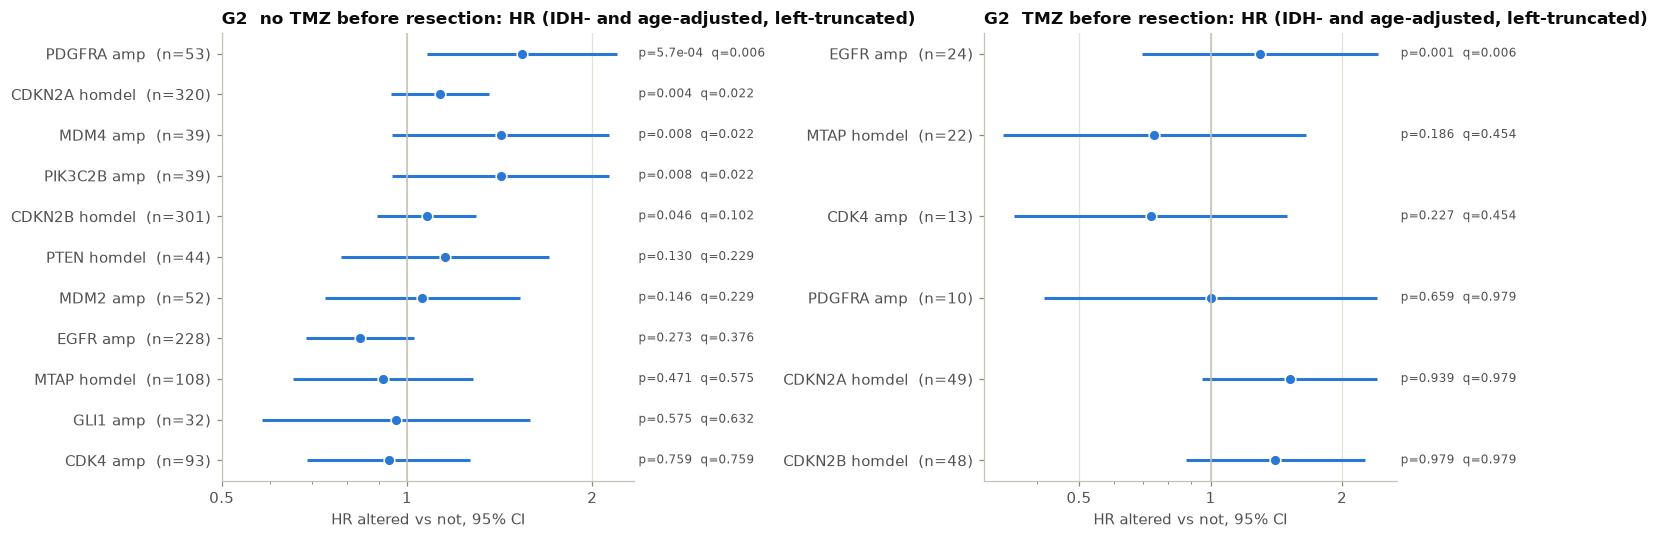

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, stratum in zip(axes, order):
    cb.forest_plot(g2[g2.stratum == stratum], top=11, title=f"G2  {stratum}: HR (IDH- and age-adjusted, left-truncated)", ax=ax)
    ax.set_xlabel("HR altered vs not, 95% CI")
fig.tight_layout()
cb.save(DS, "G2", fig=fig, slug="forest_by_tmz_group")

PosixPath('/Users/daniel/Code/explore-genie/results/dfci_glioma/G2_km_cdkn2a_mtap_by_tmz')

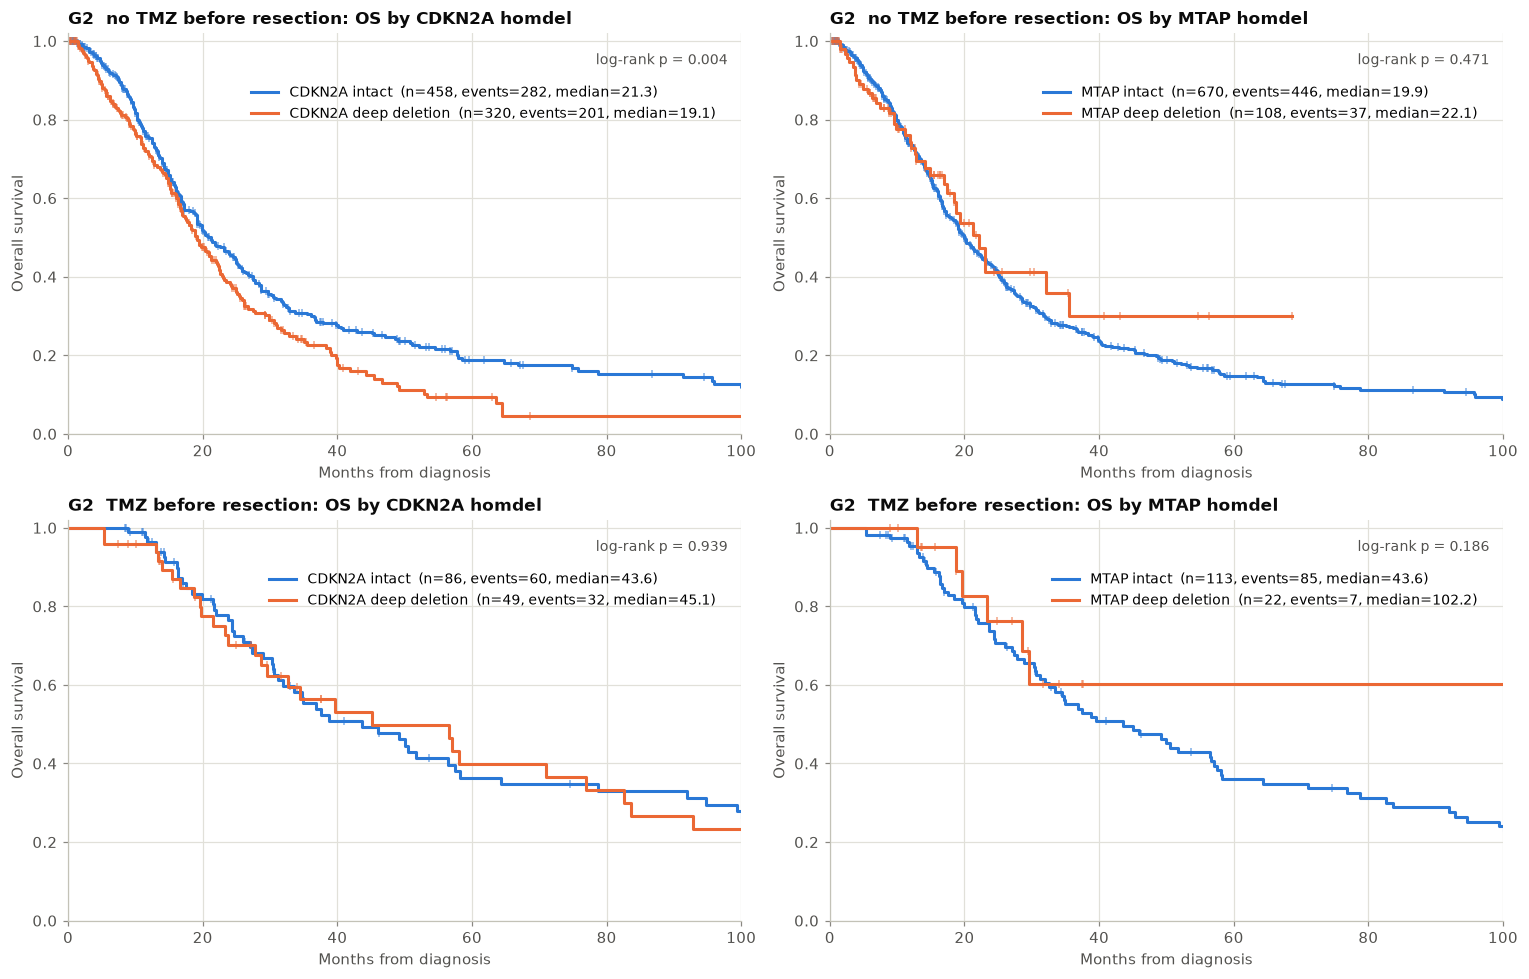

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, stratum in enumerate(order):
    for j, (g, k) in enumerate([("CDKN2A", "homdel"), ("MTAP", "homdel")]):
        d, t = cb.compare(S[S.tmz == stratum], A.status(g, k), labels=(f"{g} intact", f"{g} deep deletion"))
        cb.km_plot(d, "group", order=[f"{g} intact", f"{g} deep deletion"], ax=axes[i, j], risk_table=False,
                   title=f"G2  {stratum}: OS by {g} {k}", xlabel="Months from diagnosis", xmax=100)
fig.tight_layout()
cb.save(DS, "G2", fig=fig, slug="km_cdkn2a_mtap_by_tmz")

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,not co-deleted,784,531,22.5,0.77,0.478,0.185,0.09,NaN,NaN,NaN,NaN
1,CDKN2A + MTAP co-deleted,129,44,28.6,0.786,0.502,0.382,0.09,0.937,0.687,1.28,0.679


[G2] signal: All GBM: CDKN2A homdel 40.4% median 21.3 vs 24.6 mo, adj HR 1.22 (p=0.024); MTAP homdel 14.2% median 28.6 vs 22.5 mo, adj HR 0.94 (p=0.677); co-deletion HR 0.94 (p=0.679). Within-stratum hits at FDR<0.1: TMZ before resection: EGFR amp HR 1.30 q=0.0064; no TMZ before resection: PDGFRA amp HR 1.54 q=0.0063; no TMZ before resection: CDKN2A homdel HR 1.13 q=0.022; no TMZ before resection: MDM4 amp HR 1.42 q=0.022; no TMZ before resection: PIK3C2B amp HR 1.42 q=0.022.


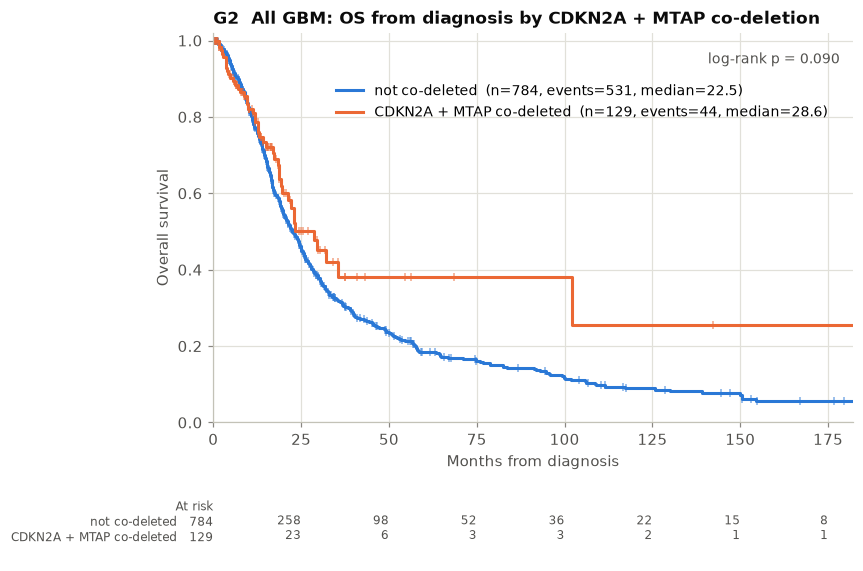

In [8]:
# CDKN2A/B + MTAP co-deletion as one feature, all GBM, adjusted
codel = (A.status("CDKN2A", "homdel") & A.status("MTAP", "homdel")).rename("codel")
d, tcd = cb.compare(S, codel, labels=("not co-deleted", "CDKN2A + MTAP co-deleted"), entry="entry", adjust=["idh", "age"])
ax, _ = cb.km_plot(d, "group", order=["not co-deleted", "CDKN2A + MTAP co-deleted"], title="G2  All GBM: OS from diagnosis by CDKN2A + MTAP co-deletion", xlabel="Months from diagnosis")
cb.save(DS, "G2", table=tcd, fig=ax.figure, slug="cdkn2a_mtap_codeletion")
display(tcd)
sig = g2[(g2.q_bh < 0.1) & (g2.stratum != "all GBM")]
cd = g2[(g2.feature == "CDKN2A homdel") & (g2.stratum == "all GBM")].iloc[0]
mt = g2[(g2.feature == "MTAP homdel") & (g2.stratum == "all GBM")].iloc[0]
cb.finding("G2", "signal" if len(sig) else "no signal at FDR<0.1 within strata",
           f"All GBM: CDKN2A homdel {cd.pct}% median {cd.median_alt} vs {cd.median_wt} mo, adj HR {cd.HR:.2f} (p={cb.fmt_p(cd.p_cox)}); MTAP homdel {mt.pct}% median {mt.median_alt} vs {mt.median_wt} mo, adj HR {mt.HR:.2f} (p={cb.fmt_p(mt.p_cox)}); "
           f"co-deletion HR {tcd.attrs['HR']:.2f} (p={cb.fmt_p(tcd.attrs['p_cox'])}). Within-stratum hits at FDR<0.1: " +
           ("; ".join(f"{r.stratum}: {r.feature} HR {r.HR:.2f} q={r.q_bh:.2g}" for r in sig.itertuples()) or "none") + ".", F)

## Summary of findings

In [9]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,G1,"replicated, but it is immortal-time bias","OS from dx: TMZ-before-resection n=135 median 45.1 vs 20.2 mo, log-rank p=6.5e-10 (deck 1.2e-8), naive HR 0.49. 135/135 TMZ-exposed samples are recurrences. OS from sample collection: median 11.5 vs 19.5 mo, p=1.3e-13; left-truncated HR 1.96, + IDH/age 1.98 (p=1.3e-08); recurrence-only from sample, adjusted: HR 3.09 (p=0.001)."
1,G2,signal,"All GBM: CDKN2A homdel 40.4% median 21.3 vs 24.6 mo, adj HR 1.22 (p=0.024); MTAP homdel 14.2% median 28.6 vs 22.5 mo, adj HR 0.94 (p=0.677); co-deletion HR 0.94 (p=0.679). Within-stratum hits at FDR<0.1: TMZ before resection: EGFR amp HR 1.30 q=0.0064; no TMZ before resection: PDGFRA amp HR 1.54 q=0.0063; no TMZ before resection: CDKN2A homdel HR 1.13 q=0.022; no TMZ before resection: MDM4 amp..."
